In [10]:

processed_path = Path("../data/processed/scg_processed.csv")

df.to_csv(processed_path, index=False)

print(f"Processed dataset saved to: {processed_path}")
print(f"Figures saved in: {FIGURE_PATH}")


Processed dataset saved to: ../data/processed/scg_processed.csv
Figures saved in: ../figures


In [9]:

# Find peaks in the Welch PSD
peaks, properties = signal.find_peaks(psd)

# Sort peaks by power
sorted_peaks = peaks[np.argsort(psd[peaks])[::-1]]

print("Top 10 dominant frequency components:\n")

for peak in sorted_peaks[:10]:
    print(
        f"Frequency: {frequencies[peak]:.3f} Hz | "
        f"Power: {psd[peak]:.8f} g²/Hz"
    )

# Find dominant frequency within individual bands
bands = {
    "Respiration": (0.1, 0.5),
    "Heartbeat": (0.8, 2.0),
    "Vibration": (5.0, 20.0)
}

print("\nDominant frequency by band:")

for name, (low, high) in bands.items():
    mask = (frequencies >= low) & (frequencies <= high)

    band_freq = frequencies[mask]
    band_psd = psd[mask]

    peak_freq = band_freq[np.argmax(band_psd)]

    print(f"{name}: {peak_freq:.3f} Hz")


Top 10 dominant frequency components:

Frequency: 0.488 Hz | Power: 0.00039020 g²/Hz
Frequency: 2.441 Hz | Power: 0.00004250 g²/Hz
Frequency: 4.883 Hz | Power: 0.00000510 g²/Hz
Frequency: 16.113 Hz | Power: 0.00000133 g²/Hz
Frequency: 110.840 Hz | Power: 0.00000006 g²/Hz
Frequency: 88.135 Hz | Power: 0.00000005 g²/Hz
Frequency: 37.598 Hz | Power: 0.00000005 g²/Hz
Frequency: 77.637 Hz | Power: 0.00000005 g²/Hz
Frequency: 26.611 Hz | Power: 0.00000005 g²/Hz
Frequency: 54.199 Hz | Power: 0.00000005 g²/Hz

Dominant frequency by band:


IndexError: boolean index did not match indexed array along axis 0; size of axis is 1025 but size of corresponding boolean axis is 513

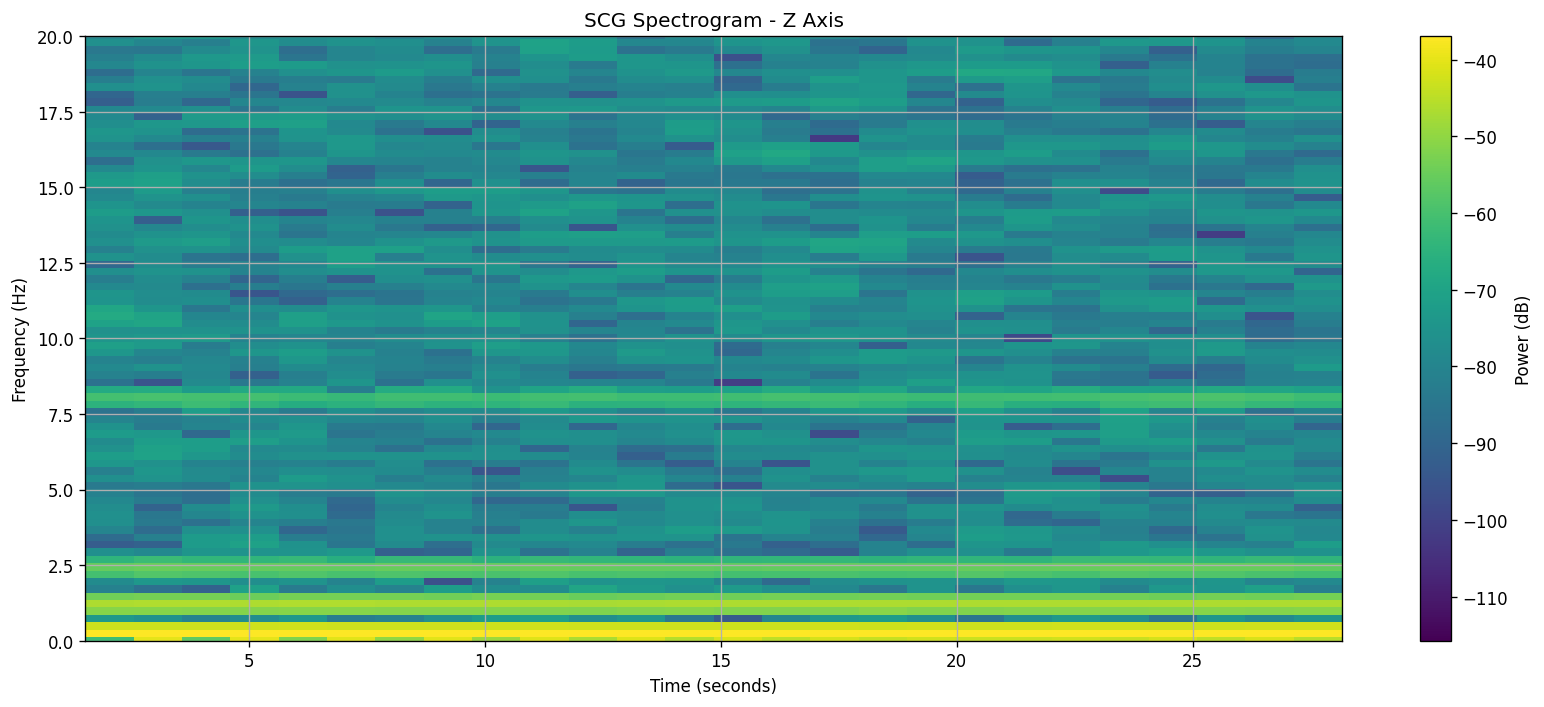

In [8]:

frequencies, times, Sxx = signal.spectrogram(
    x,
    fs=fs,
    window="hann",
    nperseg=1024,
    noverlap=768,
    scaling="density",
    mode="psd"
)

plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    frequencies,
    10 * np.log10(Sxx + 1e-15),
    shading="auto"
)

plt.ylim(0, 20)
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("SCG Spectrogram - Z Axis")

plt.colorbar(label="Power (dB)")
plt.tight_layout()

plt.savefig(FIGURE_PATH / "04_spectrogram.png")
plt.show()


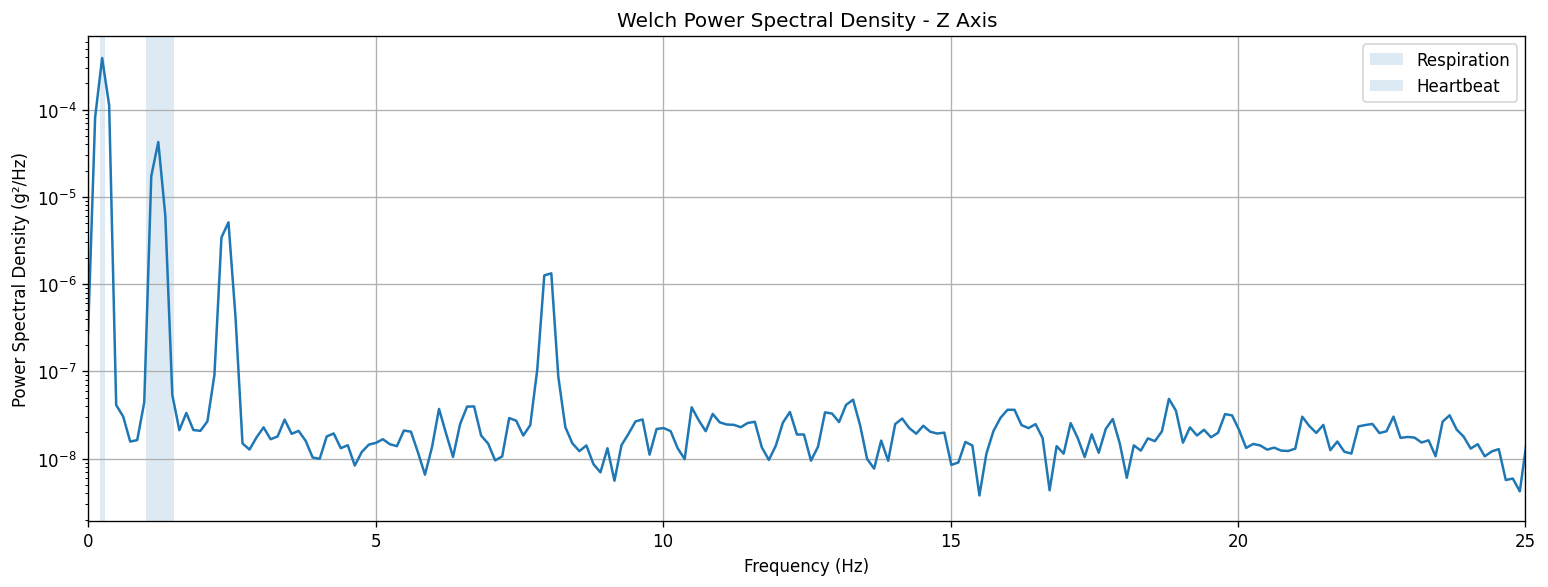

In [7]:

frequencies, psd = signal.welch(
    x,
    fs=fs,
    window="hann",
    nperseg=2048,
    noverlap=1024,
    scaling="density"
)

plt.figure(figsize=(13, 5))

plt.semilogy(frequencies, psd)

plt.xlim(0, 25)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density (g²/Hz)")
plt.title("Welch Power Spectral Density - Z Axis")

plt.axvspan(0.2, 0.3, alpha=0.15, label="Respiration")
plt.axvspan(1.0, 1.5, alpha=0.15, label="Heartbeat")

plt.legend()
plt.tight_layout()

plt.savefig(FIGURE_PATH / "03_welch_psd.png")
plt.show()


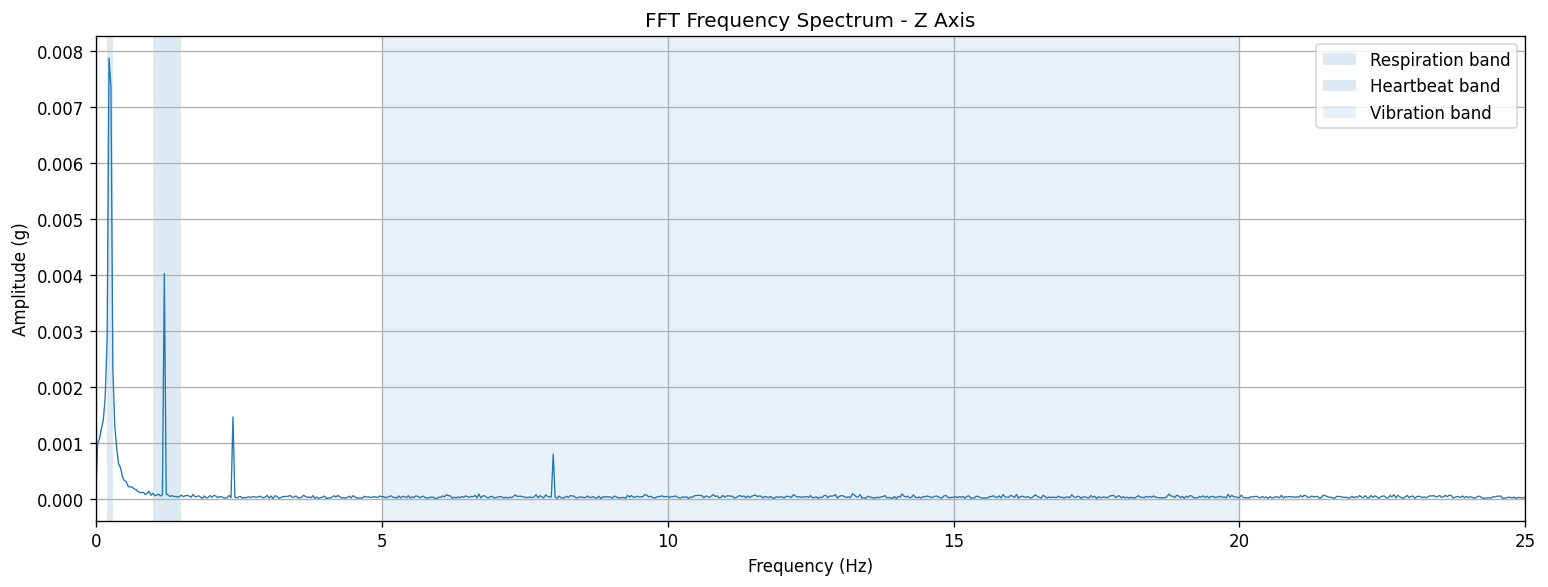

In [6]:

# Select Z-axis signal
x = df["az_g_clean"].to_numpy()

# Calculate FFT
N = len(x)

fft_values = np.fft.rfft(x)
frequencies = np.fft.rfftfreq(N, d=1/fs)

# Calculate amplitude spectrum
amplitude = (2/N) * np.abs(fft_values)
amplitude[0] /= 2

# Plot
plt.figure(figsize=(13, 5))

plt.plot(frequencies, amplitude, linewidth=0.8)

plt.xlim(0, 25)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (g)")
plt.title("FFT Frequency Spectrum - Z Axis")

plt.axvspan(0.2, 0.3, alpha=0.15, label="Respiration band")
plt.axvspan(1.0, 1.5, alpha=0.15, label="Heartbeat band")
plt.axvspan(5, 20, alpha=0.10, label="Vibration band")

plt.legend()
plt.tight_layout()

plt.savefig(FIGURE_PATH / "02_fft_spectrum.png")
plt.show()


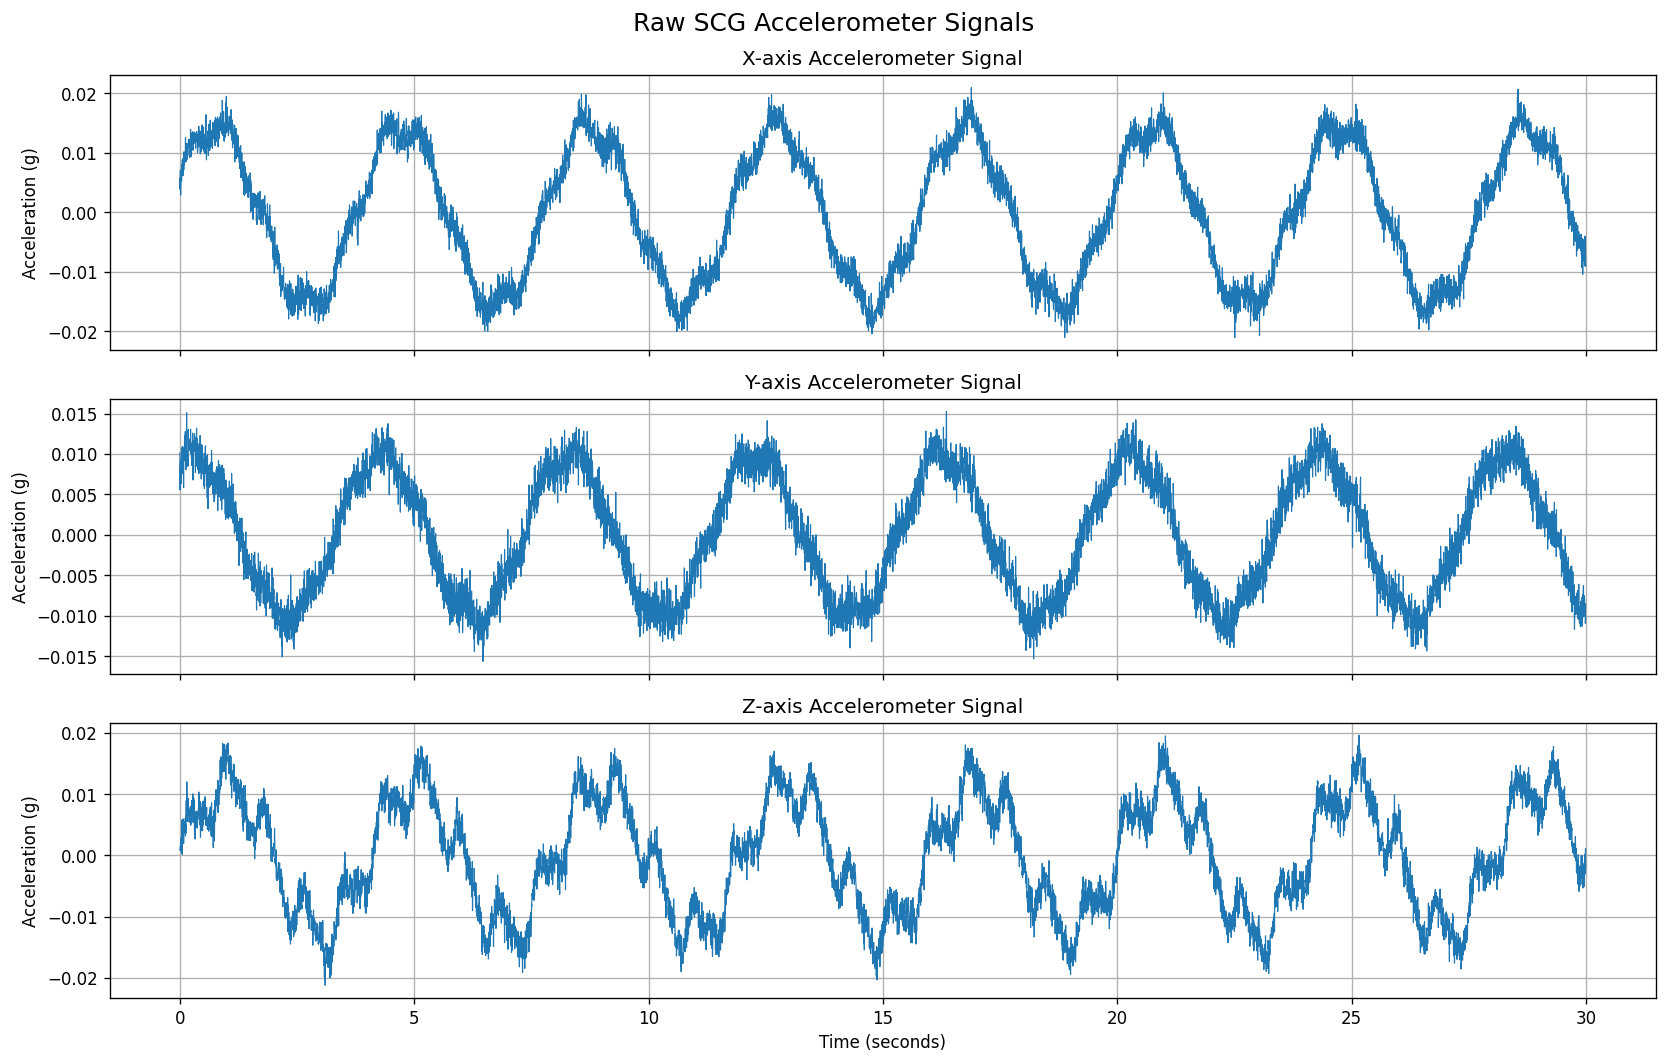

In [5]:

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

time = df["timestamp_ms"] / 1000

for ax, axis, label in zip(
    axes,
    ["ax_g_clean", "ay_g_clean", "az_g_clean"],
    ["X-axis", "Y-axis", "Z-axis"]
):
    ax.plot(time, df[axis], linewidth=0.7)
    ax.set_title(f"{label} Accelerometer Signal")
    ax.set_ylabel("Acceleration (g)")

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle("Raw SCG Accelerometer Signals", fontsize=15)
plt.tight_layout()

plt.savefig(FIGURE_PATH / "01_raw_signals.png")
plt.show()


In [4]:

# MPU6050 sensitivity for ±2g
SENSITIVITY = 16384

# Convert raw counts into acceleration in g
df["ax_g"] = df["ax_raw"] / SENSITIVITY
df["ay_g"] = df["ay_raw"] / SENSITIVITY
df["az_g"] = df["az_raw"] / SENSITIVITY

# Remove static mean offset
for axis in ["ax_g", "ay_g", "az_g"]:
    df[axis + "_clean"] = df[axis] - df[axis].mean()

display(df[["ax_g", "ay_g", "az_g",
            "ax_g_clean", "ay_g_clean", "az_g_clean"]].head())

print("Acceleration conversion completed.")


,ax_g,ay_g,az_g,ax_g_clean,ay_g_clean,az_g_clean
0,0.006287,0.010315,1.001404,0.005708,0.010142,0.000849
1,0.004456,0.005737,1.001892,0.003877,0.005564,0.001337
2,0.007263,0.008179,1.002014,0.006684,0.008006,0.001459
3,0.007690,0.009033,1.001953,0.007111,0.008860,0.001398
4,0.003479,0.009460,1.002319,0.002900,0.009288,0.001764


Acceleration conversion completed.


In [3]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check sample index continuity
index_diff = df["sample_index"].diff()

dropped_samples = df.index[index_diff > 1].tolist()

print("\nPossible dropped sample locations:", dropped_samples)

# Calculate sampling frequency from timestamps
time_s = df["timestamp_ms"].to_numpy() / 1000

time_diff = np.diff(time_s)

fs = 1 / np.median(time_diff)

duration = time_s[-1] - time_s[0]

print(f"\nSampling frequency: {fs:.2f} Hz")
print(f"Recording duration: {duration:.2f} seconds")
print(f"Total samples: {len(df)}")


Missing values:
sample_index       0
timestamp_ms       0
ax_raw             0
ay_raw             0
az_raw             0
esp32_hr_bpm    7500
esp32_rr_bpm    7500
dtype: int64

Possible dropped sample locations: []

Sampling frequency: 250.00 Hz
Recording duration: 30.00 seconds
Total samples: 7500


In [2]:

# Project directory paths
DATA_PATH = Path("../data/raw/sample_scg.csv")
FIGURE_PATH = Path("../figures")

FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# Load recording
df = pd.read_csv(DATA_PATH)

# Display first five rows
display(df.head())

print("\nDataset information:")
print(df.info())

print("\nDataset dimensions:", df.shape)


,sample_index,timestamp_ms,ax_raw,ay_raw,az_raw,esp32_hr_bpm,esp32_rr_bpm
0,0,0.0,103,169,16407,NaN,NaN
1,1,4.0,73,94,16415,NaN,NaN
2,2,8.0,119,134,16417,NaN,NaN
3,3,12.0,126,148,16416,NaN,NaN
4,4,16.0,57,155,16422,NaN,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sample_index  7500 non-null   int64  
 1   timestamp_ms  7500 non-null   float64
 2   ax_raw        7500 non-null   int64  
 3   ay_raw        7500 non-null   int64  
 4   az_raw        7500 non-null   int64  
 5   esp32_hr_bpm  0 non-null      float64
 6   esp32_rr_bpm  0 non-null      float64
dtypes: float64(3), int64(4)
memory usage: 410.3 KB
None

Dataset dimensions: (7500, 7)


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from pathlib import Path

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True

print("Libraries imported successfully!")


Libraries imported successfully!
